# Spatial extremes: a practical package walkthrough

This notebook is the first part of a complete package walkthrough. It walks through a reproducible analysis with the `spatial_extremes` package using the bundled Ontario rainfall example in `Dummy_data/`; no online data or network connection is needed.

## Sections
1. Setup and load the bundled data
2. Inspect and prepare a wide block-maxima table
3. Explore site locations and marginal observations
4. Fit GEV margins and transform to unit-Frechet
5. Summarize empirical spatial extremal dependence
6. Fit a Brown-Resnick dependence model
7. Simulate and visualize a unit-Frechet spatial field
8. Interpretation, assumptions, and next steps

For the other package methods, continue with [Max-stable models and neural estimation](./spatial_extremes_models_and_neural.ipynb) and [Bayesian workflows](./spatial_extremes_bayesian.ipynb). Together, the notebooks cover the three spatial model classes, GEV margins, pairwise maximum likelihood, both Bayesian workflows, and the optional neural estimator.

The goal is to demonstrate the end-to-end workflow and package API, not to make scientific claims from this synthetic example.

## 1. Setup and load the bundled data

For local development, install the package and plotting extra from the repository root with `python -m pip install -e ".[plotting]"`. A regular installation can use `python -m pip install "spatial-extremes[plotting]"`. The core dependencies are NumPy, SciPy, and Polars; Matplotlib is optional and is needed for the figures below.

The first cell locates the repository whether the notebook kernel starts in the repository root or in `notebooks/`. It imports the source in this checkout so that the examples exercise the package being developed.

In [12]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.spatial.distance import pdist
from scipy.stats import genextreme

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (
        path
        for path in candidates
        if (path / "Dummy_data" / "extremes_observations.parquet").is_file()
        and (path / "src" / "spatial_extremes").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from the repository "
        "or adjust PROJECT_ROOT to the checkout location."
    )
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from spatial_extremes import (
    binned_extremal_coefficient,
    fit_gev,
    fit_pairwise_likelihood,
)
from spatial_extremes.models import BrownResnickModel
from spatial_extremes.plotting import (
    plot_extremal_dependence,
    plot_spatial_field,
)

SEED = 42
observations = pl.read_parquet(
    PROJECT_ROOT / "Dummy_data" / "extremes_observations.parquet"
)
print(f"Project root: {PROJECT_ROOT}")
print(f"Observation table: {observations.shape[0]:,} rows x {observations.shape[1]} columns")
observations.head()

Project root: d:\Users\Andy Yuan\Downloads\spatial-extremes\spatial-extremes
Observation table: 10,000 rows x 6 columns


station_id,year,lon,lat,elevation_m,annual_max_mm
str,i64,f64,f64,f64,f64
"""S000""",1975,-77.356264,45.109619,408.558991,22.787672
"""S000""",1976,-77.356264,45.109619,408.558991,25.149009
"""S000""",1977,-77.356264,45.109619,408.558991,35.352321
"""S000""",1978,-77.356264,45.109619,408.558991,60.975834
"""S000""",1979,-77.356264,45.109619,408.558991,22.699549


## 2. Inspect and prepare block maxima

Each row in the bundled file is one station-year. The spatial routines expect a wide table with independent replicates (here, years) in rows and sites in columns. We select 12 stations in their original order to keep fitting quick, then explicitly use that same order for the coordinate array and wide table.

The source coordinates are longitude/latitude. For this compact area, the example below makes a local planar approximation in kilometers around 79°W, 44°N. This is suitable for a teaching illustration, not a substitute for selecting an appropriate projected coordinate reference system for real analysis.

In [13]:
print("Columns:", observations.columns)
print("Distinct stations:", observations.get_column("station_id").n_unique())
print("Year range:", observations.get_column("year").min(), "to", observations.get_column("year").max())
print("Missing annual maxima:", observations.get_column("annual_max_mm").null_count())

site_metadata = (
    observations
    .select("station_id", "lon", "lat")
    .unique(subset="station_id", maintain_order=True)
    .head(12)
)
site_names = site_metadata.get_column("station_id").to_list()

subset = observations.filter(pl.col("station_id").is_in(site_names))
wide_with_year = (
    subset
    .pivot(on="station_id", index="year", values="annual_max_mm")
    .select("year", *site_names)
    .sort("year")
)
annual_maxima = wide_with_year.select(site_names)

# Approximate local planar coordinates, in kilometers, near the study area.
longitude = site_metadata.get_column("lon").to_numpy()
latitude = site_metadata.get_column("lat").to_numpy()
coordinates = np.column_stack(
    [
        (longitude + 79.0) * 111.0 * np.cos(np.deg2rad(44.0)),
        (latitude - 44.0) * 111.0,
    ]
)

assert annual_maxima.columns == site_names
assert coordinates.shape == (len(site_names), 2)
print(f"Analysis table: {annual_maxima.shape[0]} years x {annual_maxima.shape[1]} sites")
print("Site order:", site_names)
print("Coordinate array shape:", coordinates.shape)
annual_maxima.head()

Columns: ['station_id', 'year', 'lon', 'lat', 'elevation_m', 'annual_max_mm']
Distinct stations: 200
Year range: 1975 to 2024
Missing annual maxima: 208
Analysis table: 50 years x 12 sites
Site order: ['S000', 'S001', 'S002', 'S003', 'S004', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010', 'S011']
Coordinate array shape: (12, 2)


S000,S001,S002,S003,S004,S005,S006,S007,S008,S009,S010,S011
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
22.787672,32.784759,31.284191,34.493499,29.099221,26.816139,39.397408,20.788748,20.855095,38.825658,25.718493,28.181852
25.149009,26.90914,41.247965,37.45798,27.383994,51.977282,33.943897,28.512974,28.369881,28.202324,21.639299,37.300854
35.352321,47.127707,26.491793,17.356661,20.50968,37.581957,12.603883,38.600173,19.340939,37.358307,46.777316,30.705545
60.975834,53.839579,32.404538,15.773789,25.700706,20.980871,12.159406,57.486367,22.340724,40.361763,40.761905,37.608297
22.699549,24.276816,26.95444,35.105885,23.61188,51.250712,29.663663,25.058144,27.836113,23.909215,23.191256,41.70643


## 3. Explore station locations and observations

These quick plots are useful for catching unexpected data ranges or site-selection problems before fitting. The rainfall measurements are annual maxima in millimeters.

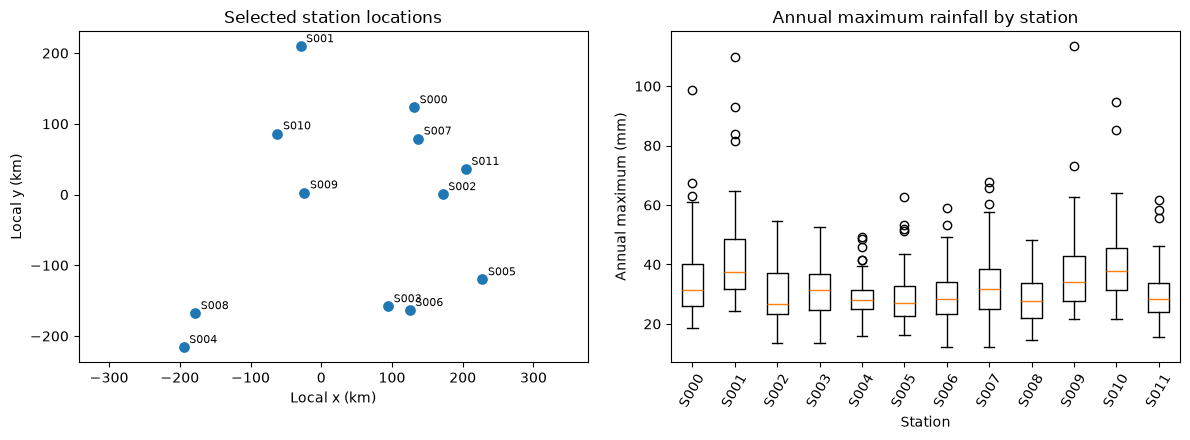

In [14]:
values = annual_maxima.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(coordinates[:, 0], coordinates[:, 1], s=45)
for name, (x, y) in zip(site_names, coordinates):
    axes[0].annotate(name, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=8)
axes[0].set(title="Selected station locations", xlabel="Local x (km)", ylabel="Local y (km)")
axes[0].set_aspect("equal", adjustable="datalim")

axes[1].boxplot([values[:, i][np.isfinite(values[:, i])] for i in range(values.shape[1])])
axes[1].set_xticks(range(1, len(site_names) + 1), site_names)
axes[1].set(title="Annual maximum rainfall by station", xlabel="Station", ylabel="Annual maximum (mm)")
axes[1].tick_params(axis="x", rotation=60)
fig.tight_layout()
plt.show()

## 4. Fit GEV margins and transform to unit-Frechet

A GEV distribution is fitted independently at each site. `fit_gev` returns a result object whose `to_unit_frechet` method applies the probability integral transform needed by the spatial dependence methods. Missing observations stay missing. The transformed values should be positive; any missing values are kept as `NaN` in the NumPy/Polars values.

The package also offers `fit_gev_by_site` for a tidy Polars summary across wide or long tables; the explicit loop here keeps the fitted result objects available for the transformations and later simulation illustration.

In [15]:
gev_fits = {
    site: fit_gev(annual_maxima.get_column(site).to_numpy())
    for site in site_names
}

gev_summary = pl.DataFrame(
    [{"site": site, **result.as_dict()} for site, result in gev_fits.items()]
)
gev_summary.select("site", "loc", "scale", "shape", "converged", "n_obs")

site,loc,scale,shape,converged,n_obs
str,f64,f64,f64,bool,i64
"""S000""",28.304753,8.125974,0.268981,true,50
"""S001""",33.88653,9.22833,0.326705,true,49
"""S002""",25.478232,7.629257,-0.015864,true,50
"""S003""",27.620168,8.77472,-0.179978,true,50
"""S004""",25.902078,5.901189,-0.027736,true,50
…,…,…,…,…,…
"""S007""",27.888112,9.141135,0.012797,true,49
"""S008""",25.067945,6.408922,-0.027554,true,50
"""S009""",30.415496,7.272523,0.352951,true,48


In [16]:
unit_frechet = pl.DataFrame(
    {
        site: gev_fits[site].to_unit_frechet(
            annual_maxima.get_column(site).to_numpy()
        )
        for site in site_names
    }
)
frechet_values = unit_frechet.to_numpy()
print("Unit-Frechet table:", unit_frechet.shape)
print("All observed transformed values are positive:", bool(np.all(frechet_values[np.isfinite(frechet_values)] > 0)))
unit_frechet.head()

Unit-Frechet table: (50, 12)
All observed transformed values are positive: True


S000,S001,S002,S003,S004,S005,S006,S007,S008,S009,S010,S011
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.472509,0.885342,2.150377,2.326428,1.726146,1.38269,6.228936,0.458166,0.521284,2.637374,0.437831,1.411079
0.663538,0.419621,8.179712,3.498155,1.286596,28.995891,2.897521,1.070716,1.68018,0.724744,0.27096,4.800545
2.180463,3.243564,1.142241,0.345939,0.405598,5.901356,0.231974,3.200006,0.413633,2.276753,3.665478,2.005935
15.261806,5.132832,2.495433,0.29863,0.966467,0.552028,0.221491,23.870304,0.65504,3.052452,2.103248,4.992187
0.46627,0.280047,1.213842,2.524839,0.679759,26.956411,1.652807,0.7333,1.544214,0.341269,0.326261,8.311406


## 5. Summarize empirical extremal dependence

The F-madogram and its related extremal coefficient summarize how often large values occur together as a function of site separation. Here we use complete years because the empirical F-madogram expects complete unit-Frechet rows. This is descriptive and does not by itself validate a model.

In [17]:
complete_mask = np.isfinite(frechet_values).all(axis=1)
complete_frechet = pl.DataFrame(
    frechet_values[complete_mask],
    schema=site_names,
    orient="row",
)
print(f"Complete years used for empirical summaries: {complete_frechet.height} / {unit_frechet.height}")

empirical_summary = binned_extremal_coefficient(
    complete_frechet,
    coordinates,
    n_bins=6,
)
empirical_summary

Complete years used for empirical summaries: 44 / 50


mean_distance,mean_extremal_coefficient,n_pairs
f64,f64,u32
61.737822,1.442639,7
143.591813,1.654385,10
215.331118,1.766172,17
287.864681,1.830764,15
365.435686,1.909673,4
430.360422,1.944466,13


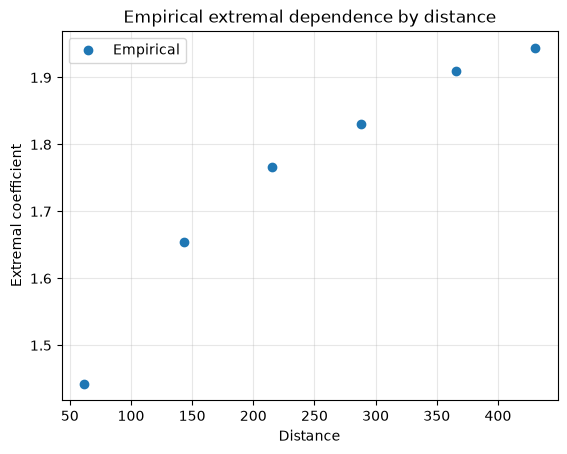

In [18]:
fig, ax = plot_extremal_dependence(
    complete_frechet,
    coordinates,
    statistic="extremal_coefficient",
    n_bins=6,
)
ax.set_title("Empirical extremal dependence by distance")
plt.show()

## 6. Fit a Brown-Resnick dependence model

`fit_pairwise_likelihood` maximizes a sum of bivariate log-likelihood contributions over pairs of sites. It accepts Polars unit-Frechet data, coordinates in the same order as the data columns, and a model class. The initial range is set from the median inter-site distance; the second free parameter starts at zero, corresponding to `alpha = 1` in this model's parameterization. A fixed seed makes any pair subsampling reproducible (all pairs are used here).

The function assumes independent replicates and stationary max-stable dependence. Convergence is an optimizer diagnostic, not proof that those assumptions fit the data.

In [19]:
initial_range = float(np.median(pdist(coordinates)))
fit = fit_pairwise_likelihood(
    BrownResnickModel,
    unit_frechet,
    coordinates,
    x0_free=np.array([np.log(initial_range), 0.0]),
    rng=np.random.default_rng(SEED),
)

print("Optimizer converged:", fit.converged)
print(f"Initial range: {initial_range:.2f} km")
print(f"Fitted range: {fit.model.range_:.2f} km")
print(f"Fitted variogram exponent (alpha): {fit.model.alpha:.3f}")
print("Site pairs used:", fit.n_pairs_used)
print("Replicates:", fit.n_replicates)
print(f"Composite negative log-likelihood: {fit.nllh:.2f}")

Optimizer converged: True
Initial range: 245.82 km
Fitted range: 68.70 km
Fitted variogram exponent (alpha): 0.894
Site pairs used: 66
Replicates: 50
Composite negative log-likelihood: 13790.82


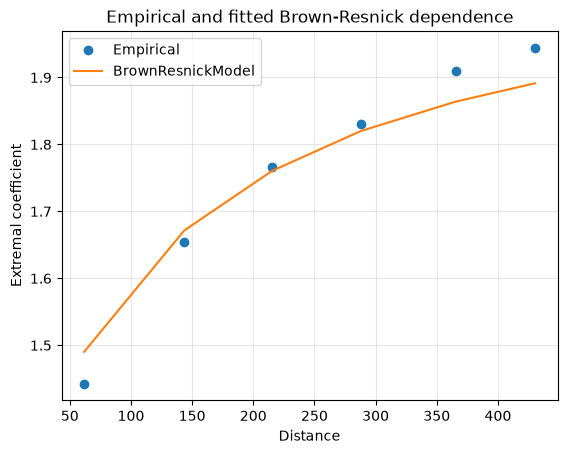

In [20]:
fig, ax = plot_extremal_dependence(
    complete_frechet,
    coordinates,
    model=fit.model,
    statistic="extremal_coefficient",
    n_bins=6,
)
ax.set_title("Empirical and fitted Brown-Resnick dependence")
plt.show()

## 7. Simulate and visualize a spatial field

The model simulator returns a spatial field with **unit-Frechet margins**, not rainfall in millimeters. `plot_spatial_field` displays the values at the observed locations; it does not interpolate them to a continuous surface. The final cell shows a one-site illustration of how the fitted marginal GEV can map a unit-Frechet value back to millimeters.

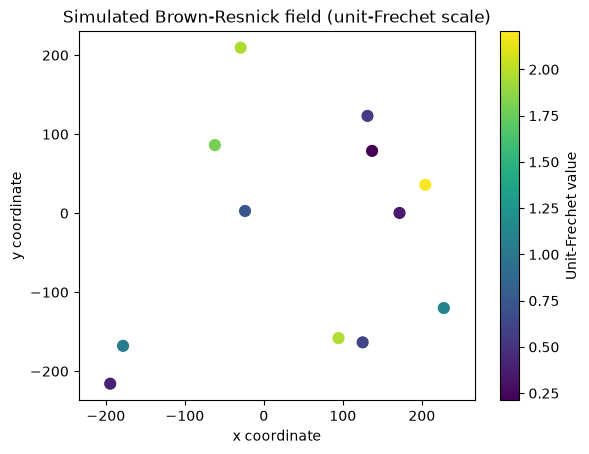

In [21]:
simulated_frechet = fit.model.simulate(
    coordinates,
    n_reps=1,
    rng=np.random.default_rng(SEED),
)[0]
fig, ax = plot_spatial_field(
    simulated_frechet,
    coordinates,
    title="Simulated Brown-Resnick field (unit-Frechet scale)",
    colorbar_label="Unit-Frechet value",
)
plt.show()

In [22]:
site_index = 0
site = site_names[site_index]
marginal_fit = gev_fits[site]
u = np.exp(-1.0 / simulated_frechet[site_index])
simulated_mm_at_site = genextreme.ppf(
    u,
    c=-marginal_fit.shape,
    loc=marginal_fit.loc,
    scale=marginal_fit.scale,
)
print(f"Illustrative back-transform at {site}: {simulated_mm_at_site:.2f} mm")
print("This uses only that site's fitted GEV and is not a package-wide inverse-margin transform.")

Illustrative back-transform at S000: 23.94 mm
This uses only that site's fitted GEV and is not a package-wide inverse-margin transform.


## 8. Interpretation, assumptions, and next steps

- The bundled data are synthetic: their generator includes a time trend in location and uses a Gaussian-copula spatial construction. A stationary max-stable model is therefore an intentionally imperfect working model for this walkthrough. Treat fitted values as a demonstration, not scientific estimates.
- The GEV fits are stationary and independent site-by-site. Trends, covariates, and uncertainty propagation are not included in this two-stage workflow.
- Pairwise fitting assumes independent replicates, unit-Frechet margins, and correctly ordered projected coordinates. Missingness is handled pair-by-pair for the fit; empirical F-madogram plots use complete rows.
- The package also provides Smith and Schlather max-stable models, other dependence summaries, an approximate curvature-adjusted pairwise posterior, and optional Bayesian spatio-temporal GEV margins. The Bayesian margin functionality needs `python -m pip install "spatial-extremes[bayesian]"`; it describes marginal distributions and is not a substitute for modeling residual spatial dependence.
- Optional neural estimation is available with the `neural` extra. Geographic map plotting needs the `maps` extra and an internet connection; neither is required in this notebook.

For a real analysis, choose a scientifically appropriate block definition and projected coordinate system, investigate trends and missingness, compare plausible dependence models, check optimizer diagnostics and sensitivity, and validate assumptions before interpreting return levels or joint risk.